# Sales Data Analysis

This notebook explores the Superstore dataset to understand sales patterns, profitability, and customer segments.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/superstore.csv",encoding="latin1")



In [14]:
print("First 5 rows:")
print(df.head())

First 5 rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0     

In [13]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Shape:", df.shape)


Rows: 9994
Columns: 21
Shape: (9994, 21)


In [17]:

print(df.columns)
print(df.columns.tolist())

print(df.dtypes)

df.info()



Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales   

In [20]:

#print(df.describe())
print(df.describe(include="all"))


             Row ID        Order ID Order Date   Ship Date       Ship Mode  \
count   9994.000000            9994       9994        9994            9994   
unique          NaN            5009       1237        1334               4   
top             NaN  CA-2017-100111   9/5/2016  12/16/2015  Standard Class   
freq            NaN              14         38          35            5968   
mean    4997.500000             NaN        NaN         NaN             NaN   
std     2885.163629             NaN        NaN         NaN             NaN   
min        1.000000             NaN        NaN         NaN             NaN   
25%     2499.250000             NaN        NaN         NaN             NaN   
50%     4997.500000             NaN        NaN         NaN             NaN   
75%     7495.750000             NaN        NaN         NaN             NaN   
max     9994.000000             NaN        NaN         NaN             NaN   

       Customer ID  Customer Name   Segment        Country     

In [22]:

print(df[["Product Name", "Sales", "Profit"]])


                                           Product Name     Sales    Profit
0                     Bush Somerset Collection Bookcase  261.9600   41.9136
1     Hon Deluxe Fabric Upholstered Stacking Chairs,...  731.9400  219.5820
2     Self-Adhesive Address Labels for Typewriters b...   14.6200    6.8714
3         Bretford CR4500 Series Slim Rectangular Table  957.5775 -383.0310
4                        Eldon Fold 'N Roll Cart System   22.3680    2.5164
...                                                 ...       ...       ...
9989                             Ultra Door Pull Handle   25.2480    4.1028
9990  Tenex B1-RE Series Chair Mats for Low Pile Car...   91.9600   15.6332
9991                              Aastra 57i VoIP phone  258.5760   19.3932
9992  It's Hot Message Books with Stickers, 2 3/4" x 5"   29.6000   13.3200
9993  Acco 7-Outlet Masterpiece Power Center, Wihtou...  243.1600   72.9480

[9994 rows x 3 columns]


In [38]:
high_sales = df[df["Sales"] > 500]
print(high_sales)

      Row ID        Order ID Order Date   Ship Date       Ship Mode  \
1          2  CA-2016-152156 2016-11-08  11/11/2016    Second Class   
3          4  US-2015-108966 2015-10-11  10/18/2015  Standard Class   
7          8  CA-2014-115812 2014-06-09   6/14/2014  Standard Class   
10        11  CA-2014-115812 2014-06-09   6/14/2014  Standard Class   
11        12  CA-2014-115812 2014-06-09   6/14/2014  Standard Class   
...      ...             ...        ...         ...             ...   
9931    9932  CA-2015-104948 2015-11-13  11/17/2015  Standard Class   
9942    9943  CA-2014-143371 2014-12-28    1/3/2015  Standard Class   
9947    9948  CA-2017-121559 2017-06-01    6/3/2017    Second Class   
9948    9949  CA-2017-121559 2017-06-01    6/3/2017    Second Class   
9968    9969  CA-2017-153871 2017-12-11  12/17/2017  Standard Class   

     Customer ID    Customer Name    Segment        Country             City  \
1       CG-12520      Claire Gute   Consumer  United States        

In [29]:
print("Unique products:", df["Product Name"].nunique())
print(df["Product Name"].unique())


Unique products: 1850
<StringArray>
[                               'Bush Somerset Collection Bookcase',
      'Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back',
        'Self-Adhesive Address Labels for Typewriters by Universal',
                    'Bretford CR4500 Series Slim Rectangular Table',
                                   'Eldon Fold 'N Roll Cart System',
 'Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood',
                                                       'Newell 322',
                                   'Mitel 5320 IP Phone VoIP phone',
             'DXL Angle-View Binders with Locking Rings by Samsill',
                                 'Belkin F5C206VTEL 6 Outlet Surge',
 ...
  'Self-Adhesive Address Labels for Typewriters with Dispenser Box',
             'Office Star - Task Chair with Contemporary Loop Arms',
                                              'Grip Seal Envelopes',
                              'Penpower WorldCard Pro Card Sca

In [44]:
df["Region"].value_counts()

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

In [31]:
print(df["Category"].value_counts())

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64


In [33]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [36]:

df["Order Date"] = pd.to_datetime(df["Order Date"])

print(df["Order Date"].dtype)


datetime64[us]


In [37]:

top_sales = df.sort_values(
    by="Sales",
    ascending=False
).head(5)

print(top_sales)


      Row ID        Order ID Order Date   Ship Date       Ship Mode  \
2697    2698  CA-2014-145317 2014-03-18   3/23/2014  Standard Class   
6826    6827  CA-2016-118689 2016-10-02   10/9/2016  Standard Class   
8153    8154  CA-2017-140151 2017-03-23   3/25/2017     First Class   
2623    2624  CA-2017-127180 2017-10-22  10/24/2017     First Class   
4190    4191  CA-2017-166709 2017-11-17  11/22/2017  Standard Class   

     Customer ID Customer Name      Segment        Country           City  \
2697    SM-20320   Sean Miller  Home Office  United States   Jacksonville   
6826    TC-20980  Tamara Chand    Corporate  United States      Lafayette   
8153    RB-19360  Raymond Buch     Consumer  United States        Seattle   
2623    TA-21385  Tom Ashbrook  Home Office  United States  New York City   
4190    HL-15040  Hunter Lopez     Consumer  United States         Newark   

      ... Postal Code   Region       Product ID    Category Sub-Category  \
2697  ...       32216    South  TE

Data Cleaning

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/superstore.csv",encoding="latin1")

print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [60]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
total_exoense = total_sales - total_profit
print(f"Total Expense: ${total_exoense:,.2f}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Expense: $2,010,803.84


In [61]:

print("Average Sales:", df["Sales"].mean())
print("Highest Sales:", df["Sales"].max())
print("Lowest Sales:", df["Sales"].min())


Average Sales: 229.85800083049827
Highest Sales: 22638.48
Lowest Sales: 0.444


In [63]:

print("Unique Orders:", df["Order ID"].nunique())
print("Unique Products:", df["Product Name"].nunique())


Unique Orders: 5009
Unique Products: 1850


In [65]:

#category_sales = df.groupby("Category")["Sales"].sum()
city_sales = df.groupby("City")["Sales"].sum()

#print(category_sales)
print(city_sales)


City
Aberdeen         25.500
Abilene           1.392
Akron          2729.986
Albuquerque    2220.160
Alexandria     5519.570
                 ...   
Woonsocket      195.550
Yonkers        7657.666
York            817.978
Yucaipa          50.800
Yuma            840.865
Name: Sales, Length: 531, dtype: float64


In [67]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales)

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)


Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [68]:
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [69]:

category_summary = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Average_Sales=("Sales", "mean"),
          Total_Quantity=("Quantity", "sum")
      )
)

print(category_summary.round(2))


                 Total_Sales  Total_Profit  Average_Sales  Total_Quantity
Category                                                                 
Furniture          741999.80      18451.27         349.83            8028
Office Supplies    719047.03     122490.80         119.32           22906
Technology         836154.03     145454.95         452.71            6939


In [ ]:

sales_pivot = pd.pivot_table(df,values="Sales",index="Category",columns="Region",aggfunc="sum",fill_value=0)

print(sales_pivot)


Region               Central        East       South         West
Category                                                         
Furniture        163797.1638  208291.204  117298.684  252612.7435
Office Supplies  167026.4150  205516.055  125651.313  220853.2490
Technology       170416.3120  264973.981  148771.908  251991.8320


In [73]:

df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
      .sum()
)

print(monthly_sales)


Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


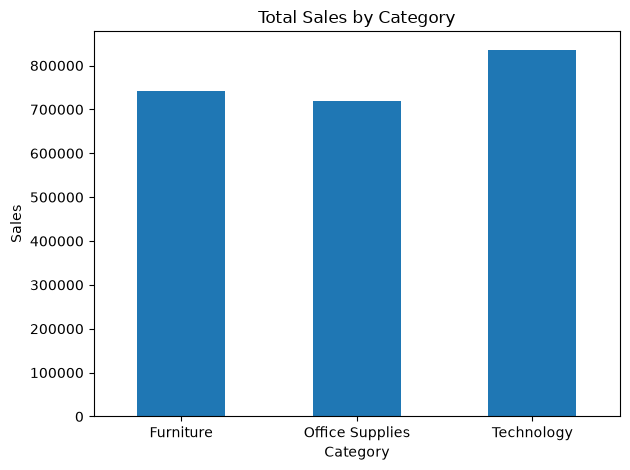

In [95]:

category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


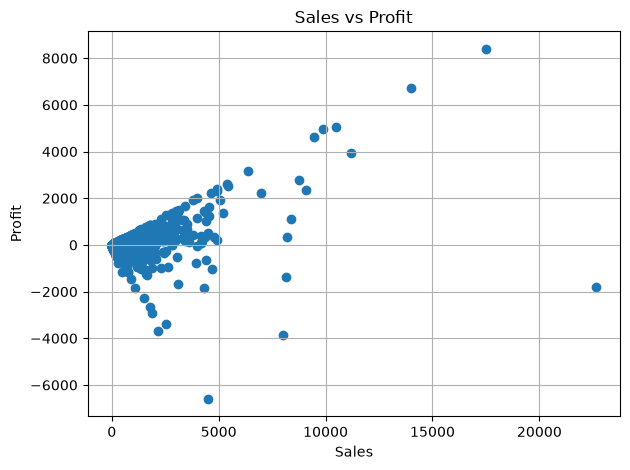

In [98]:

plt.scatter(df["Sales"], df["Profit"])

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.grid(True)
plt.tight_layout()
plt.show()


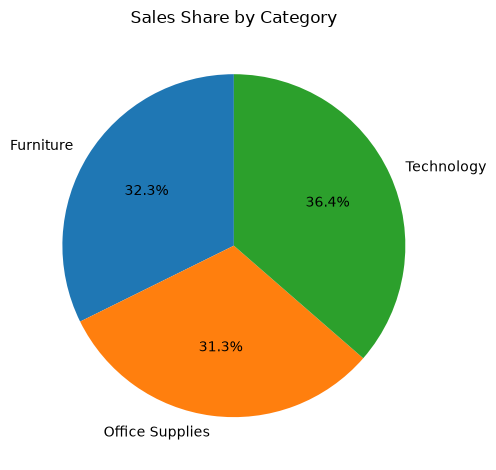

In [99]:

category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Share by Category")
plt.ylabel("")
plt.tight_layout()
plt.show()


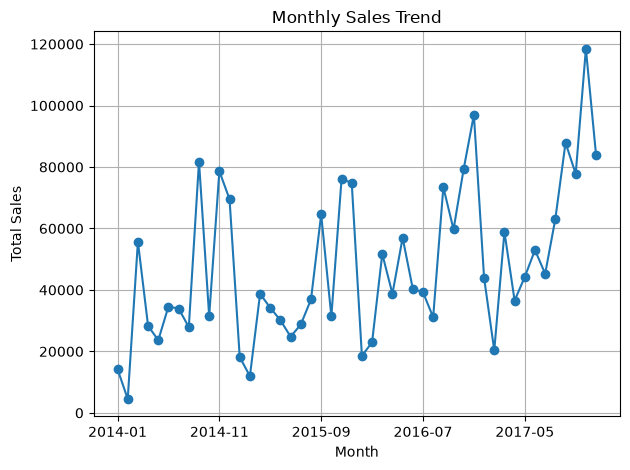

In [100]:

df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()


End